In [17]:
%pip install pandas scikit-learn matplotlib


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [18]:
from sklearn.datasets import load_breast_cancer

df = load_breast_cancer(as_frame=True).frame
df = df.rename(columns={"target": "class"})

X = df.drop(columns="class")
y = df["class"]

print(df.head())


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [19]:
print(df.isna().sum().sum())

0


In [20]:
from sklearn.model_selection import train_test_split

# Split the data into a train dataset and a test dataset:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=6, stratify=y
)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


In [21]:
from sklearn.tree import DecisionTreeClassifier

# Build and fit a decision tree model:

model = DecisionTreeClassifier(random_state=7)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",7
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [22]:
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

# Compute metrics:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))

Accuracy: 0.956
              precision    recall  f1-score   support

           0       0.91      0.98      0.94        42
           1       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



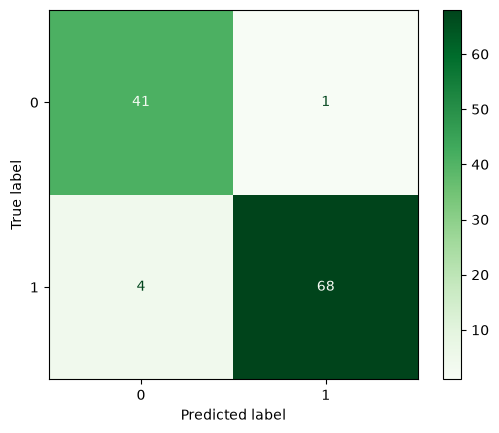

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap="Greens")

In [24]:
# For assessing overfitting:
model.score(X_train, y_train)   # Results: 1.0 (train) vs. 0.956 (test, above) => mild overfitting

1.0

In [25]:
# The actual depth of unrestricted tree:
model.get_depth()

6

In [26]:
import pandas as pd
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold

# General Set-up (for Set-up 1 below):
# Hold out 20% of the data as test_data (stratified), train on the rest of the data.
# For each max_depth:
#   For train_data:
#       stratified 5-fold CV (5 fits), repeated 5 times (5 fits x 5 = 25 fits);
#       score of each fit = mean f1_score of f1_scores, wherein each f1_score is per class;
#       mean f1_score = mean of 25 validation f1 scores.
# Pick the max_depth with the best mean f1_score.
# Refit the best model on whole training data, then evaluate on the test data.

# Set-up 1: param_grid = {"max_depth": [2, 3, 4, 5, 6, 8, 10, None]}
# Problem: leaves with very few samples, such as 1.
# Action: a parameter - min_samples_leaf - has also been passed into the grid model (see Set-up 2).


# Set-up 2:
param_grid = {
    "max_depth": [2, 3, 4, 5, None],
    "min_samples_leaf": [1, 2, 3, 5]
    }

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=5)   # shuffles by default
print(cv.get_n_splits(X_train, y_train))    # n_splits = 25

grid = GridSearchCV(model, param_grid, cv=cv, scoring="f1_macro") # f1_macro - unweighted (w.r.t. classes) mean of f1 scores

grid.fit(X_train, y_train)

print(grid.best_params_, round(grid.best_score_, 3)) 

# print(grid.cv_results_.keys())
pd.DataFrame(grid.cv_results_)[["param_max_depth", "param_min_samples_leaf", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False)


25
{'max_depth': 4, 'min_samples_leaf': 2} 0.925


,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
9,4,2,0.924688,0.025478
12,5,1,0.923030,0.026440
8,4,1,0.922640,0.024502
14,5,3,0.921106,0.023824
7,3,5,0.920765,0.028205
13,5,2,0.920760,0.027439
18,None,3,0.919730,0.023939
15,5,5,0.919730,0.031735
19,None,5,0.919324,0.031842
11,4,5,0.917883,0.031195


In [27]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))
print("Train accuracy:", round(best_model.score(X_train, y_train), 3))

              precision    recall  f1-score   support

           0       0.93      0.95      0.94        42
           1       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114

Train accuracy: 0.985


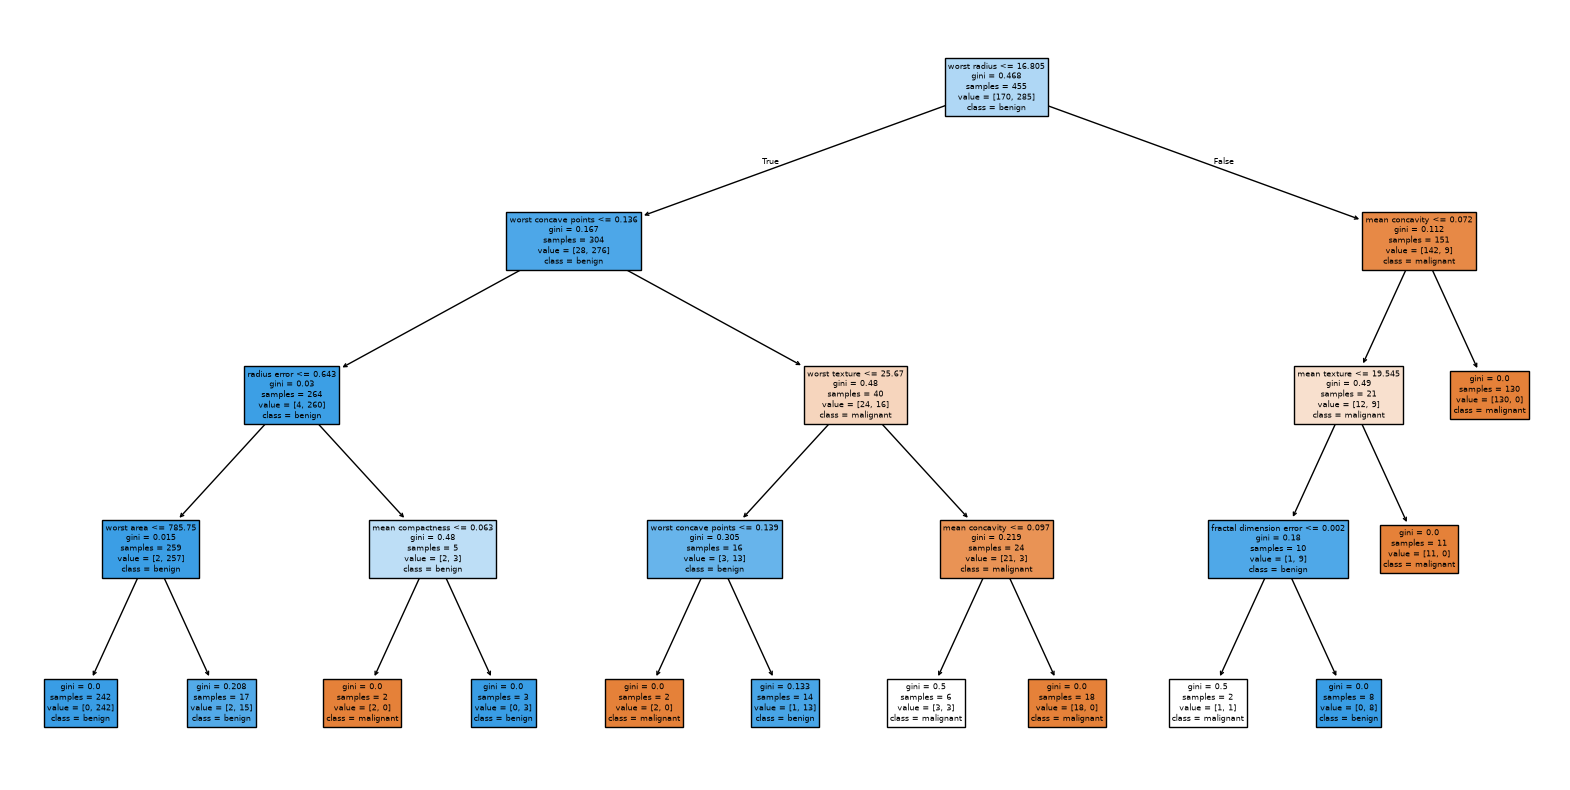

In [28]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
plot_tree(best_model, feature_names=X.columns, class_names=["malignant", "benign"], filled=True)
plt.show()

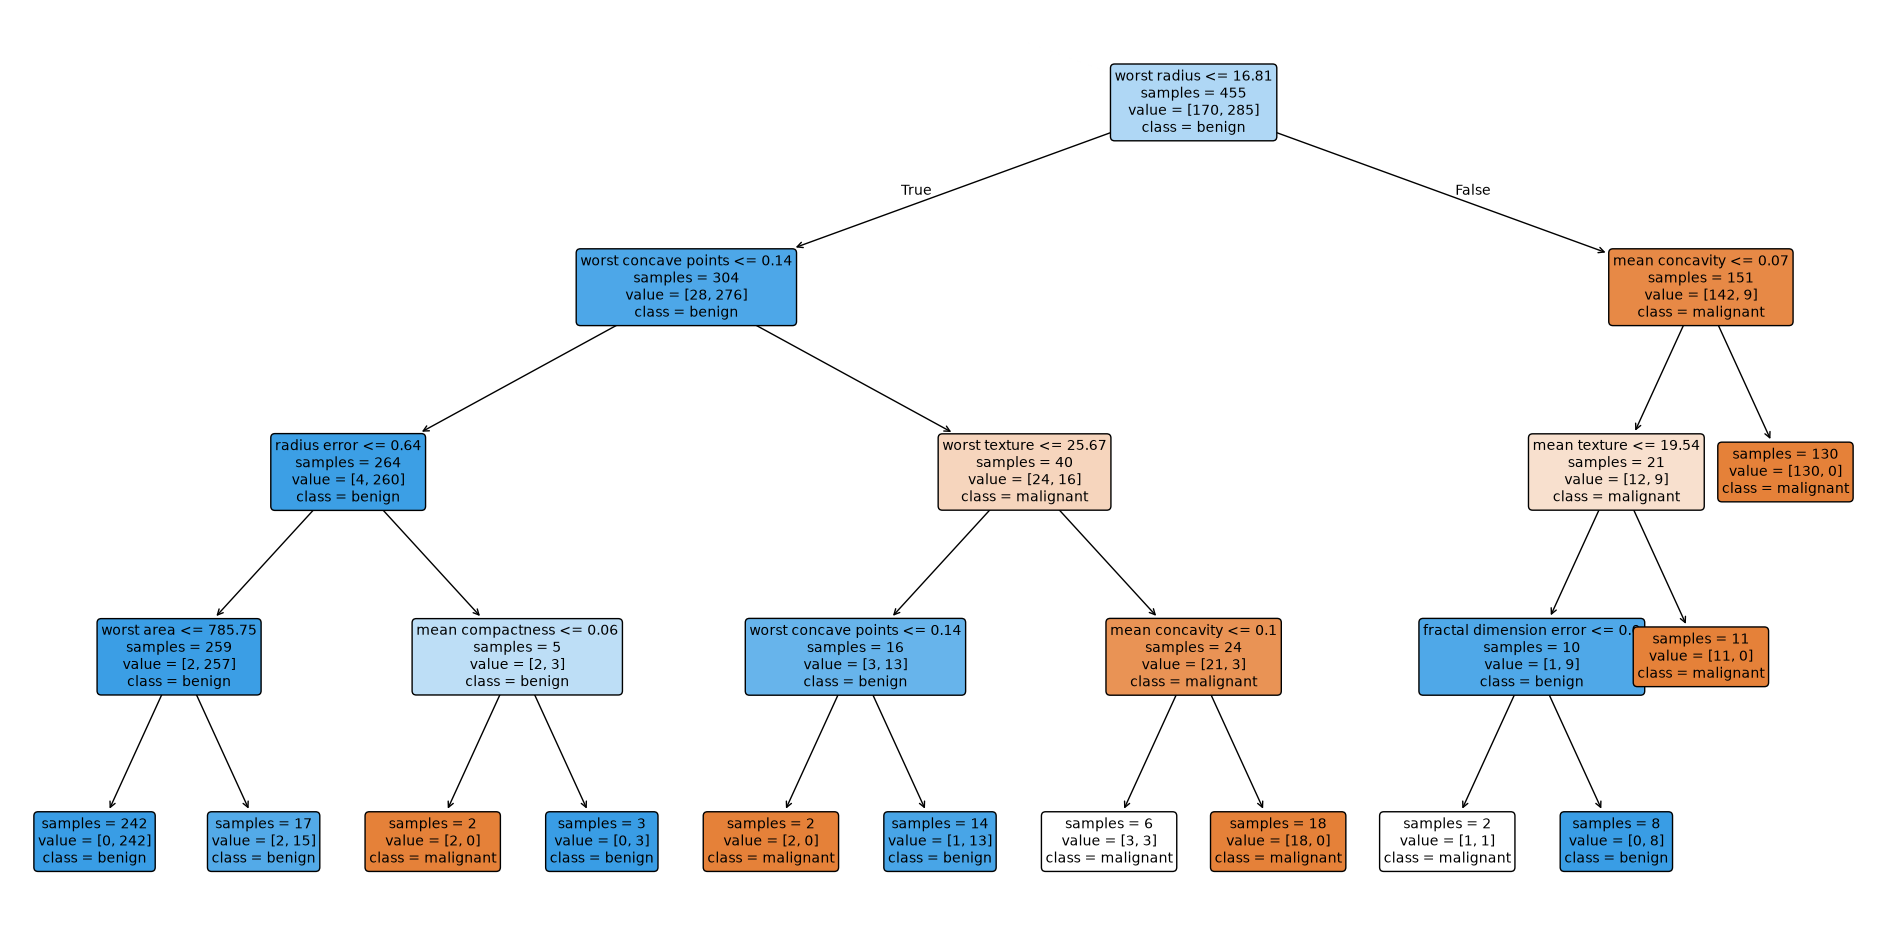

In [29]:
# Plot for a poster:
fig, ax = plt.subplots(figsize=(24, 12))

plot_tree(
    best_model,
    feature_names=X.columns,
    class_names=["malignant", "benign"],  # assumes class 0=malignant, 1=benign
    filled=True,
    rounded=True,
    proportion=False,
    impurity=False,
    precision=2,
    fontsize=10,
    ax=ax,
)

fig.savefig("cancer_tree_poster.png", dpi=300, bbox_inches="tight")
plt.show()

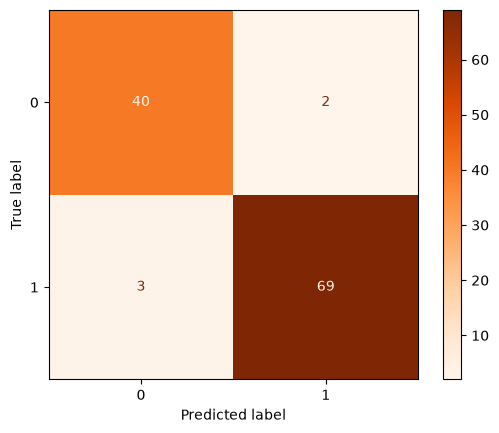

In [30]:
# Confusion matrix for the final model
final_model = best_model
ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test, cmap="Oranges")

In [31]:
# Feature importance - how much each feature reduces impurity across the split
importance = pd.Series(final_model.feature_importances_, index=X.columns)
print(importance.sort_values(ascending=False).head(7))

worst radius            0.713221
worst concave points    0.131551
worst texture           0.044577
mean concavity          0.043675
mean texture            0.041682
mean compactness        0.011789
radius error            0.007416
dtype: float64


In [ ]:
# Compare the predictions of the compressed decision set with the predicitions of
# the final tree model:

import re

raw = open("compressed_cancer_BK.txt").read().replace('"', '')
rules = [(c, int(k)) for c, k in re.findall(r"= \((.*), (\d+)\)\s*$", raw, re.M)]

# Rule literals contain underscores, but the model was fitted on column names without underscores
# Create a new df (copy of X_test), where the cols are renamed to match the literals of compressed_cancer_BK.txt
X_rules = X_test.rename(columns=lambda c: c.replace(" ", "_"))

rule_pred = pd.Series(index=X_test.index, dtype="float")
for cond, k in rules:   # k - is a class label
    rule_pred[X_rules.eval(cond)] = k

print("Agreement:", (final_model.predict(X_test) == rule_pred).mean(), "| unmatched:", rule_pred.isna().sum())

Agreement: 1.0 | unmatched: 0
